### downloading MOD16A2GF

In [2]:
import ee

ee.Initialize()

# ======================
# ROI
# ======================
roi = ee.FeatureCollection(
    "projects/lithe-inscriber-448612-q7/assets/tekeze"
)

# ======================
# MOD16 PET
# ======================
col = (ee.ImageCollection("MODIS/061/MOD16A2GF")
       .select("PET")
       .filterDate("2024-01-01", "2025-12-31")
       .filterBounds(roi)
)

# ======================
# Convert to monthly sum (important!)
# ======================
def monthly_pet(year, month):
    start = ee.Date.fromYMD(year, month, 1)
    end = start.advance(1, "month")

    img = (col.filterDate(start, end)
             .sum()
             .multiply(0.1)   # MOD16 scale factor (important)
             .clip(roi)
             .set("system:time_start", start.millis()))

    return img

# ======================
# Build image collection
# ======================
years = ee.List.sequence(2024, 2025)
months = ee.List.sequence(1, 12)

def build_collection(y):
    y = ee.Number(y)
    return months.map(lambda m: monthly_pet(y, m))

pet_collection = ee.ImageCollection.fromImages(
    years.map(build_collection).flatten()
)

# ======================
# EXPORT LOOP
# ======================
size = pet_collection.size().getInfo()
images = pet_collection.toList(size)

folder = "GEE_MOD16_PET_Tekeze2025"

for i in range(size):

    img = ee.Image(images.get(i))

    date = ee.Date(img.get("system:time_start")).format("YYYY_MM").getInfo()

    filename = f"PET_{date}"

    task = ee.batch.Export.image.toDrive(
        image=img,
        description=filename,
        folder=folder,
        fileNamePrefix=filename,
        region=roi.geometry(),
        scale=1000,
        crs="EPSG:4326",
        maxPixels=1e13
    )

    task.start()
    print("Started:", filename)

Started: PET_2024_01
Started: PET_2024_02
Started: PET_2024_03
Started: PET_2024_04
Started: PET_2024_05
Started: PET_2024_06
Started: PET_2024_07
Started: PET_2024_08
Started: PET_2024_09
Started: PET_2024_10
Started: PET_2024_11
Started: PET_2024_12
Started: PET_2025_01
Started: PET_2025_02
Started: PET_2025_03
Started: PET_2025_04
Started: PET_2025_05
Started: PET_2025_06
Started: PET_2025_07
Started: PET_2025_08
Started: PET_2025_09
Started: PET_2025_10
Started: PET_2025_11
Started: PET_2025_12


### visualize PET for 2010

Files found: 12


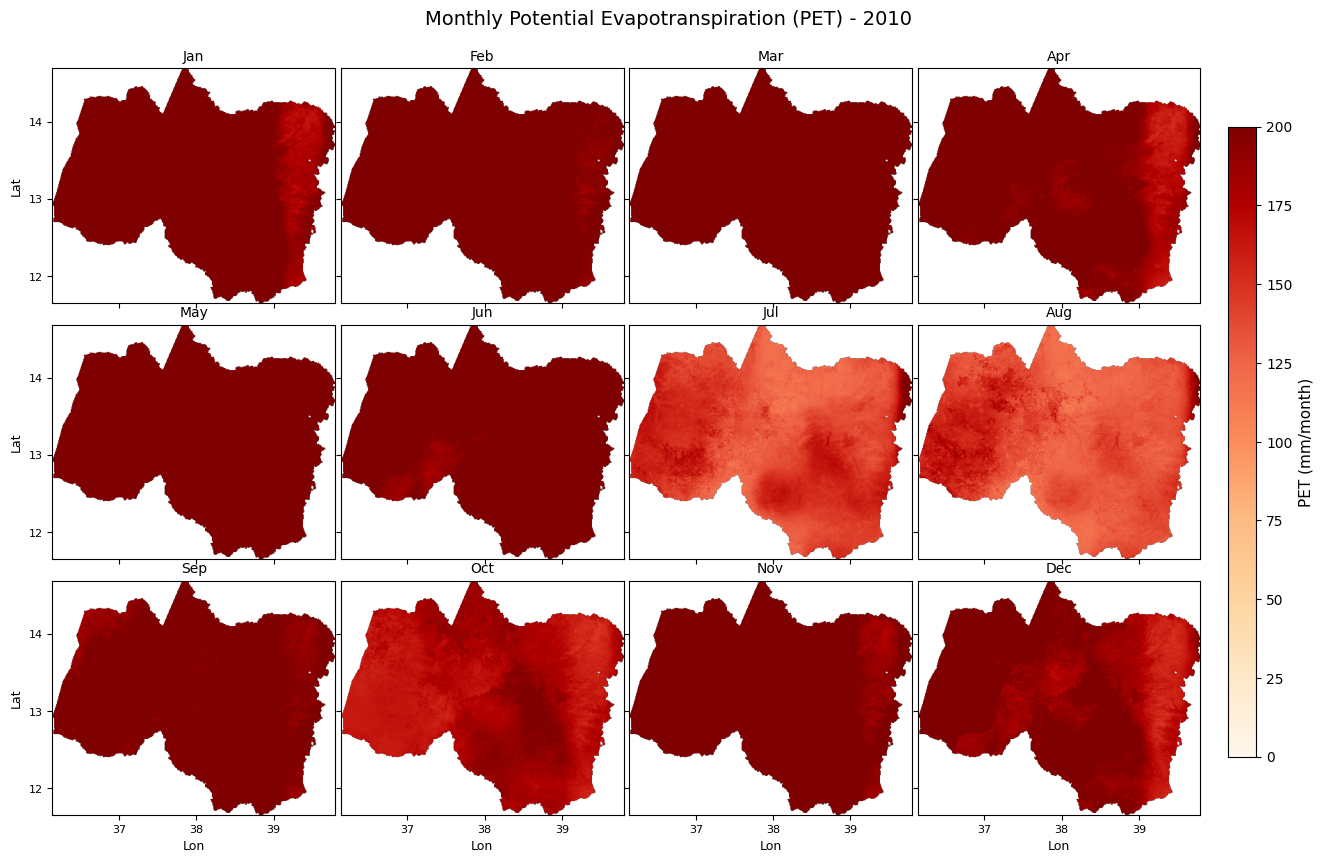

In [3]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ======================
# Folder
# ======================
folder = r"C:\Users\gerii\Documents\projects\tekeze\MOD16"

files = sorted([
    f for f in os.listdir(folder)
    if f.startswith("PET_2010") and f.endswith(".tif")
])

print("Files found:", len(files))

# ======================
# Figure
# ======================
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
axes = axes.flatten()

months = ["Jan","Feb","Mar","Apr","May","Jun",
          "Jul","Aug","Sep","Oct","Nov","Dec"]

# ======================
# PET range (adjust if needed)
# ======================
vmin = 0
vmax = 200   # mm/month typical — adjust if needed

# ======================
# Plot
# ======================
for i, f in enumerate(files):

    path = os.path.join(folder, f)

    with rasterio.open(path) as src:
        data = src.read(1).astype("float32")

        # mask invalid
        data[data < 0] = np.nan

        bounds = src.bounds
        extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

    ax = axes[i]

    im = ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap="OrRd",   # PET style (heat/evaporation)
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(months[i], fontsize=10)

    # ======================
    # 1-degree ticks
    # ======================
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.tick_params(labelsize=8)

    # ======================
    # Axis styling
    # ======================
    row = i // 4
    col = i % 4

    if col == 0:
        ax.set_ylabel("Lat", fontsize=9)
    else:
        ax.set_yticklabels([])

    if row == 2:
        ax.set_xlabel("Lon", fontsize=9)
    else:
        ax.set_xticklabels([])

# ======================
# Remove empty axes
# ======================
for j in range(len(files), 12):
    axes[j].axis("off")

# ======================
# Layout (tight)
# ======================
plt.subplots_adjust(
    left=0.06,
    right=0.88,
    top=0.92,
    bottom=0.08,
    wspace=0.02,
    hspace=0.05
)

# ======================
# Colorbar (right side)
# ======================
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("PET (mm/month)", fontsize=11)

# ======================
# Title
# ======================
plt.suptitle("Monthly Potential Evapotranspiration (PET) - 2010", fontsize=14)

# ======================
# Save
# ======================
fig.canvas.draw()
fig.savefig(
    r"C:\Users\gerii\Documents\projects\tekeze\MOD16\PET_2010_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()